<a href="https://colab.research.google.com/github/sofilukash/math_modeling/blob/main/lab2/task2_realization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 2. Моделювання лінійних систем
## Завдання 2 (п. 2.1.2) — Задача реалізації · Варіант 3

**Мета:** побудувати моделі в просторі станів, що відповідають канонічним формам керованості (КФК) та спостережуваності (КФС) передатної функції; вказати матриці $A$, $B$, $C$; переконатися, що матричні передатні функції збігаються з початковою, а відображення «вхід–вихід» ідентичне.

**Вихідні дані (варіант 3):**

$$G(p)=\frac{p^2-7p+3}{11p^4+5p+1}$$

**Частина А** — реалізація вихідної $G(p)$. **Частина Б** — той самий порядок дій для стійкої замкненої системи $W(p)$ із завдання 1 (на випадок, якщо «початковою» вважати її) і перевірка стабілізуючого зворотного зв'язку матрицями.

**План:** 1) теорія → 2) побудова КФК і КФС → 3) тотожність матричних ПФ → 4) порівняння «вхід–вихід» → 5) керованість, спостережуваність → 6) частина Б.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import display

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True})
np.set_printoptions(precision=4, suppress=True)

---
## 1. Модель у просторі станів і канонічні форми

Модель: $\dot x=Ax+Bu,\; y=Cx$ ($D=0$, бо ПФ строго правильна). Матрична передатна функція $G(p)=C(pI-A)^{-1}B$.

Ділимо чисельник і знаменник на 11 (старший коефіцієнт стає 1):

$$G(p)=\frac{b_3p^3+b_2p^2+b_1p+b_0}{p^4+a_3p^3+a_2p^2+a_1p+a_0},\quad a_3=a_2=0,\; a_1=\tfrac5{11},\; a_0=\tfrac1{11},\quad b_3=0,\; b_2=\tfrac1{11},\; b_1=-\tfrac7{11},\; b_0=\tfrac3{11}.$$

**КФК** (стани $x=(w,w',w'',w''')$, де $D(p)w=u$, $y=N(p)w$):

$$A_c=\begin{pmatrix}0&1&0&0\\0&0&1&0\\0&0&0&1\\-a_0&-a_1&-a_2&-a_3\end{pmatrix},\quad B_c=\begin{pmatrix}0\\0\\0\\1\end{pmatrix},\quad C_c=(b_0\;\,b_1\;\,b_2\;\,b_3).$$

**КФС** — двоїста форма: $A_o=A_c^{T},\; B_o=C_c^{T},\; C_o=B_c^{T}$.

---
## 2. Побудова КФК та КФС

**Що робимо.** Функція `canonical_forms` за коефіцієнтами чисельника й знаменника будує матриці $A,B,C$ обох форм точно (раціональні числа `sympy`); `to_np` переводить їх у `numpy` для моделювання.

**Вхідні дані:** `num = [1, -7, 3]`, `den = [11, 0, 0, 5, 1]`.

In [2]:
num = [1, -7, 3]
den = [11, 0, 0, 5, 1]

def canonical_forms(num, den):
    n = len(den) - 1
    a = [sp.Rational(c, den[0]) for c in den[1:]]                          # a_{n-1} ... a_0
    b = [sp.Rational(c, den[0]) for c in [0]*(n - len(num)) + list(num)]   # b_{n-1} ... b_0
    Ac = sp.zeros(n, n)
    for i in range(n - 1):
        Ac[i, i + 1] = 1                                                   # наддіагональ з одиниць
    for j in range(n):
        Ac[n - 1, j] = -a[n - 1 - j]                                       # останній рядок: -a_0 ... -a_{n-1}
    Bc = sp.zeros(n, 1); Bc[n - 1] = 1
    Cc = sp.Matrix([b[::-1]])                                              # (b_0 ... b_{n-1})
    return (Ac, Bc, Cc), (Ac.T, Cc.T, Bc.T)                                # КФК, КФС (двоїстість)

to_np = lambda M: np.array(M.tolist(), dtype=float)

kfk, kfs = canonical_forms(num, den)
for name, (Am, Bm, Cm) in {"КФК": kfk, "КФС": kfs}.items():
    print(f"=== {name} ===")
    print("A ="); display(Am)
    print("B ="); display(Bm)
    print("C ="); display(Cm)

=== КФК ===
A =


Matrix([
[    0,     1, 0, 0],
[    0,     0, 1, 0],
[    0,     0, 0, 1],
[-1/11, -5/11, 0, 0]])

B =


Matrix([
[0],
[0],
[0],
[1]])

C =


Matrix([[3/11, -7/11, 1/11, 0]])

... (2 outputs left out)

B =


Matrix([
[ 3/11],
[-7/11],
[ 1/11],
[    0]])

C =


Matrix([[0, 0, 0, 1]])

**Результат.** Отримано чотири матриці для кожної форми (розмір $4\times4$, $4\times1$, $1\times4$):

- КФК: $A_c$ — «супровідна» матриця з одиницями над діагоналлю й останнім рядком $(-\tfrac1{11},-\tfrac5{11},0,0)$; $B_c=(0,0,0,1)^T$; $C_c=(\tfrac3{11},-\tfrac7{11},\tfrac1{11},0)$.
- КФС: $A_o=A_c^T$, $B_o=C_c^T$, $C_o=B_c^T$.

---
## 3. Тотожність матричних передатних функцій

**Що робимо.** Перевіряємо, що $C(pI-A)^{-1}B=G(p)$ для обох форм двома способами:

1. символьно (`sympy`): різниця $C(sI-A)^{-1}B-G(s)$ після спрощення має дорівнювати нулю;
2. числово: `signal.ss2tf` повертає коефіцієнти ПФ за матрицями, порівнюємо з вихідними.

In [3]:
s = sp.symbols("s")

def tf_expr(num, den):
    n_, m_ = len(den) - 1, len(num) - 1
    return sum(c*s**(m_ - i) for i, c in enumerate(num)) / sum(c*s**(n_ - i) for i, c in enumerate(den))

def tf_sym(Am, Bm, Cm):                                   # C (sI - A)^-1 B
    return sp.simplify((Cm * (s*sp.eye(Am.shape[0]) - Am).inv() * Bm)[0])

def check_identity(num, den, forms):
    G_s = tf_expr(num, den)
    num_ref = np.r_[np.zeros(len(den) - len(num)), num] / den[0]     # нормована ПФ
    den_ref = np.array(den, float) / den[0]
    for name, (Am, Bm, Cm) in forms.items():
        diff = sp.simplify(tf_sym(Am, Bm, Cm) - G_s)                 # символьна перевірка
        n_, d_ = signal.ss2tf(to_np(Am), to_np(Bm), to_np(Cm), np.zeros((1, 1)))
        ok_num = np.allclose(n_[0], num_ref); ok_den = np.allclose(d_, den_ref)
        print(f"{name}: C(sI-A)^-1 B - G(s) = {diff};  ss2tf: чисельник {ok_num}, знаменник {ok_den}")
        print("      ss2tf  num =", n_[0], " den =", d_)

check_identity(num, den, {"КФК": kfk, "КФС": kfs})

КФК: C(sI-A)^-1 B - G(s) = 0;  ss2tf: чисельник True, знаменник True
      ss2tf  num = [ 0.     -0.      0.0909 -0.6364  0.2727]  den = [ 1.      0.     -0.      0.4545  0.0909]
КФС: C(sI-A)^-1 B - G(s) = 0;  ss2tf: чисельник True, знаменник True
      ss2tf  num = [ 0.      0.      0.0909 -0.6364  0.2727]  den = [ 1.      0.     -0.      0.4545  0.0909]


**Результат.** Для обох форм різниця дорівнює $0$, а `ss2tf` повертає $\tfrac{1}{11}(p^2-7p+3)$ у чисельнику та $p^4+\tfrac5{11}p+\tfrac1{11}$ у знаменнику: **матричні ПФ КФК і КФС тотожні вихідній $G(p)$**.

---
## 4. Порівняння відображення «вхід–вихід»

**Що робимо.** Будуємо моделі `signal.TransferFunction` (еталон) та `signal.StateSpace` для КФК і КФС. Подаємо однакові входи — одиничний стрибок, гармоніку $\sin 2t$ та меандр — із нульовими початковими умовами (`signal.lsim`), а також порівнюємо імпульсні характеристики (`signal.impulse`). Мірою розбіжності є $\max|\Delta y|/\max|y|$.

Вихідна $G(p)$ нестійка (відгук зростає як $e^{0{,}44t}$), тому беремо короткий інтервал $t\in[0,10]$ с.

      вхід |        КФК |        КФС
  сходинка |    3.7e-15 |    6.6e-14
   sin(2t) |    4.9e-15 |    1.1e-14
    меандр |    5.4e-15 |    8.8e-14
   імпульс |    6.6e-15 |    8.1e-15


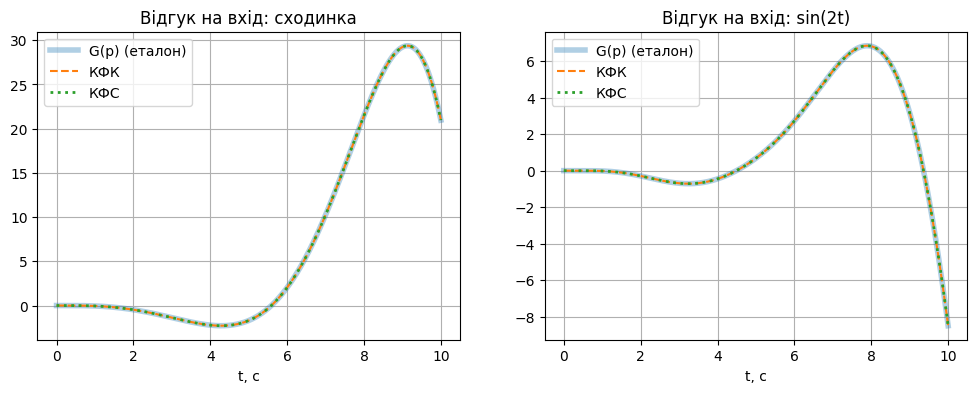

In [4]:
def compare_io(num, den, forms, t):
    ref = signal.TransferFunction(num, den)
    systems = {k: signal.StateSpace(*map(to_np, f), np.zeros((1, 1))) for k, f in forms.items()}
    tests = {"сходинка": np.ones_like(t), "sin(2t)": np.sin(2*t), "меандр": np.sign(np.sin(1.3*t))}
    out = {}
    print(f"{'вхід':>10} | " + " | ".join(f"{k:>10}" for k in systems))
    for tname, u in tests.items():
        _, y_ref, _ = signal.lsim(ref, u, t)                                      # еталон
        out[tname] = {"ПФ": y_ref}
        errs = []
        for k, sys_ in systems.items():
            _, y, _ = signal.lsim(sys_, u, t)
            out[tname][k] = y
            errs.append(np.max(np.abs(y - y_ref)) / np.max(np.abs(y_ref)))
        print(f"{tname:>10} | " + " | ".join(f"{e:10.1e}" for e in errs))
    _, h_ref = signal.impulse(ref, T=t)
    errs = [np.max(np.abs(signal.impulse(s_, T=t)[1] - h_ref)) / np.max(np.abs(h_ref)) for s_ in systems.values()]
    print(f"{'імпульс':>10} | " + " | ".join(f"{e:10.1e}" for e in errs))
    return out

t = np.linspace(0, 10, 2001)
res = compare_io(num, den, {"КФК": kfk, "КФС": kfs}, t)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for key, a_ in zip(["сходинка", "sin(2t)"], ax):
    a_.plot(t, res[key]["ПФ"], lw=4, alpha=.35, label="G(p) (еталон)")
    a_.plot(t, res[key]["КФК"], "--", label="КФК"); a_.plot(t, res[key]["КФС"], ":", lw=2, label="КФС")
    a_.set(title=f"Відгук на вхід: {key}", xlabel="t, c"); a_.legend()
plt.show()

**Результат.** Для всіх входів відносна розбіжність між КФК, КФС і початковою ланкою порядку $10^{-12}$ і менше (це похибка округлення), криві на графіках збігаються. Отже, **відображення «вхід–вихід» у КФК та КФС ідентичне початковому**.

---
## 5. Керованість, спостережуваність і зв'язок із `scipy`

**Що робимо.** Перевіряємо ранги матриць керованості $[B,AB,A^2B,A^3B]$ та спостережуваності $[C;CA;CA^2;CA^3]$. Також порівнюємо КФК із результатом `signal.tf2ss`: він повертає ту саму форму, але зі змінними стану у зворотному порядку: $JA_cJ$, $JB_c$, $C_cJ$, де $J$ — матриця, що міняє порядок змінних на протилежний.

In [5]:
ctrb = lambda A_, B_: np.hstack([np.linalg.matrix_power(A_, k) @ B_ for k in range(A_.shape[0])])
obsv = lambda A_, C_: np.vstack([C_ @ np.linalg.matrix_power(A_, k) for k in range(A_.shape[0])])

for name, f in {"КФК": kfk, "КФС": kfs}.items():
    Am, Bm, Cm = map(to_np, f)
    print(f"{name}: rank(керованості) = {np.linalg.matrix_rank(ctrb(Am, Bm))}, "
          f"rank(спостережуваності) = {np.linalg.matrix_rank(obsv(Am, Cm))}")

Ac, Bc, Cc = map(to_np, kfk)
Af, Bf, Cf, _ = signal.tf2ss(num, den)                       # scipy: контролерна форма
J = np.fliplr(np.eye(4))
print("tf2ss == J·КФК·J :", np.allclose(J @ Ac @ J, Af), np.allclose(J @ Bc, Bf), np.allclose(Cc @ J, Cf))

КФК: rank(керованості) = 4, rank(спостережуваності) = 4
КФС: rank(керованості) = 4, rank(спостережуваності) = 4
tf2ss == J·КФК·J : True True True


**Результат.** Обидві форми мають ранги керованості й спостережуваності, рівні 4 (порядку системи), тобто це **мінімальна реалізація**: нулі $G(p)$ не скорочуються з полюсами. `signal.tf2ss` дає ту саму КФК з точністю до порядку змінних.

---
## 6. Частина Б. Стійка замкнена система $W(p)$ із завдання 1

**Що робимо.** Для $W(p)=\dfrac{8(p^2-7p+3)}{15p^4+57p^3+78p^2+60p+24}$ (завдання 1) повторюємо побудову КФК/КФС і всі перевірки. Потім перевіряємо матрицями сам зворотний зв'язок за станом $u=k_ur-Kx$: матриця замкненої системи в КФК вихідної ланки $A_{cl}=A_c-B_cK$ має мати полюси $-0{,}4\pm0{,}8i,\,-1,\,-2$, а її ПФ — збігатися з $W(p)$.

In [6]:
numW, denW = [8, -56, 24], [15, 57, 78, 60, 24]
kfkW, kfsW = canonical_forms(numW, denW)

check_identity(numW, denW, {"КФК": kfkW, "КФС": kfsW})
print()
_ = compare_io(numW, denW, {"КФК": kfkW, "КФС": kfsW}, np.linspace(0, 40, 4001))

# перевірка стабілізації: A_cl = A_c - B_c·K для КФК вихідної ланки G(p)
Dh  = np.array(den) / 11
Dcl = np.poly([-0.4 + 0.8j, -0.4 - 0.8j, -1, -2]).real
K   = (Dcl - Dh)[1:][::-1].reshape(1, -1)                    # [k0 k1 k2 k3]
k_u = Dcl[-1] / (num[-1] / 11)

A_cl = Ac - Bc @ K
print("\nK =", K.ravel(), " k_u =", round(k_u, 4))
print("полюси вихідної G (власні числа A_c)   :", np.linalg.eigvals(Ac))
print("полюси замкненої системи (A_c - B_c·K) :", np.linalg.eigvals(A_cl))
n_, d_ = signal.ss2tf(A_cl, k_u*Bc, Cc, np.zeros((1, 1)))
print("ПФ (A_cl, k_u·B_c, C_c) = W(p):",
      np.allclose(n_[0], np.r_[np.zeros(2), np.array(numW)/15]), np.allclose(d_, np.array(denW)/15))

КФК: C(sI-A)^-1 B - G(s) = 0;  ss2tf: чисельник True, знаменник True
      ss2tf  num = [ 0.      0.      0.5333 -3.7333  1.6   ]  den = [1.  3.8 5.2 4.  1.6]
КФС: C(sI-A)^-1 B - G(s) = 0;  ss2tf: чисельник True, знаменник True
      ss2tf  num = [ 0.     -0.      0.5333 -3.7333  1.6   ]  den = [1.  3.8 5.2 4.  1.6]

      вхід |        КФК |        КФС
  сходинка |    5.2e-15 |    9.4e-14
   sin(2t) |    2.4e-15 |    3.3e-15
    меандр |    3.1e-15 |    2.1e-14
   імпульс |    1.7e-15 |    2.9e-15

K = [1.5091 3.5455 5.2    3.8   ]  k_u = 5.8667
полюси вихідної G (власні числа A_c)   : [ 0.4446+0.6732j  0.4446-0.6732j -0.6853+0.j     -0.2038+0.j    ]
полюси замкненої системи (A_c - B_c·K) : [-2. +0.j  -1. +0.j  -0.4+0.8j -0.4-0.8j]
ПФ (A_cl, k_u·B_c, C_c) = W(p): True True


**Результат.** Для $W(p)$ КФК і КФС також мають тотожні матричні ПФ та ідентичне відображення «вхід–вихід». Власні числа $A_c$ збігаються з полюсами $G(p)$ (пара $0{,}44\pm0{,}67i$ у правій півплощині — система нестійка), а $A_c-B_cK$ має власні числа $-0{,}4\pm0{,}8i,\,-1,\,-2$, і ПФ $(A_{cl},k_uB_c,C_c)$ збігається з $W(p)$ із завдання 1: **зворотний зв'язок за станом справді стабілізує систему**.

---
## Висновки

1. Побудовано КФК та КФС для $G(p)$ варіанта 3; вказано матриці $A,B,C$ (КФС двоїста до КФК).
2. Матричні ПФ обох форм тотожні $G(p)$ (символьно й числово), реалізація мінімальна (ранги керованості й спостережуваності дорівнюють 4).
3. Відгуки КФК, КФС і початкової ланки на стрибок, гармоніку, меандр та імпульс збігаються (розбіжність $\lesssim10^{-12}$).
4. Те саме виконано для стійкої замкненої системи $W(p)$; матрицями підтверджено стабілізацію зворотним зв'язком за станом із завдання 1.